# Land cover statistics

Follow along with the [lesson on the course website](https://meds-eds-220.github.io/MEDS-eds-220-course/book/chapters/lesson-17-raster-wrangling/lesson-17-raster-wrangling.html). The lesson page has the data sources and where to download the data from.

## About the data

- **Land cover:** Impact Observatory 10 m Annual Land Use Land Cover (9-class) V2 maps, accessed through the Microsoft Planetary Computer (MPC) STAC catalog. Nothing to download.
- **Fire perimeters:** Eaton and Palisades fires, January 2025.
- **California state boundary.**
- **Land cover class labels:** a CSV with the code, name and official color of each class.

Download the `Eaton_Perimeter_20250121`, `Palisades_Perimeter_20250121` and `ca_state_boundary` folders and the `io-lulc-9-class-labels.csv` file from the course's Google Drive. Add them to a `data` directory next to this notebook.

**Before class:** run the next two cells and make sure all the data imports without errors.

## Fire perimeter preparation

Import the libraries:

In [ ]:
import os

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import geopandas as gpd
import rioxarray as rioxr
from shapely import box # makes polygon

import pystac_client # connect to stac
import planetary_computer # specific library for planetary image

from IPython.display import Image # display pretty image

Import the data:

In [2]:
# UPDATE THIS AS NEEDED SO YOU CAN IMPORT THE DATA

# Fire perimeters
eaton = gpd.read_file(os.path.join('data',
                                   'land-cover-stats-data',
                                   'Eaton_Perimeter_20250121',
                                   'Eaton_Perimeter_20250121.shp')
                                   )
palisades = gpd.read_file(os.path.join('data',
                                       'land-cover-stats-data', 
                                       'Palisades_Perimeter_20250121',
                                       'Palisades_Perimeter_20250121.shp')
                                       )

# California state boundary
ca = gpd.read_file(os.path.join('data',
                                'land-cover-stats-data', 
                                'ca_state_boundary',
                                'ca_state_boundary.shp'))

# Land cover class codes, names and colors
labels = pd.read_csv(os.path.join('data', 'land-cover-stats-data', 'io-lulc-9-class-labels.csv'))

## Catalog search

- We search with a bounding box: a list `[xmin, ymin, xmax, ymax]` in EPSG:4326.
- Our bounding box comes from the Eaton Fire perimeter.

EPSG:3857
(20, 5)


<Axes: >

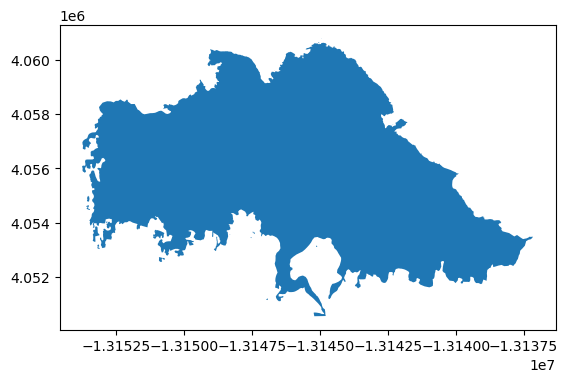

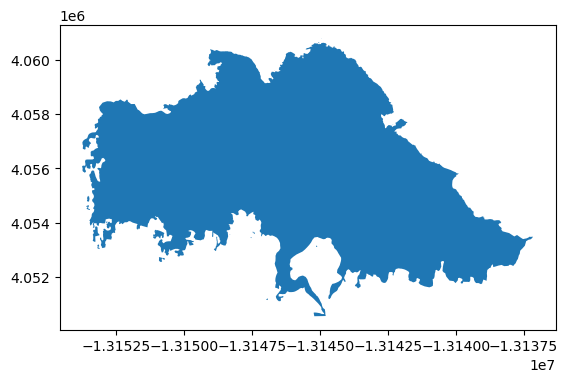

In [ ]:
print(eaton.crs)
print(eaton.shape)
eaton.plot()

In [15]:
# Create list of bounding box coords for search in 4326 CRS
eaton_bbox = list(eaton.to_crs('epsg:4326').total_bounds)

Connect to the MPC catalog. The collection ID for the land cover data is `io-lulc-annual-v02`:

In [12]:
# Open MPC data catalog
catalog = pystac_client.Client.open(
    "https://planetarycomputer.microsoft.com/api/stac/v1",
    modifier=planetary_computer.sign_inplace,
)

In [17]:
# Search MPC Catalogue
search = catalog.search(collections=['io-lulc-annual-v02'],
                        bbox=eaton_bbox, 
                        datetime='2023')

In [19]:
# Retrieve search items
items = search.item_collection()
print(f"Returned {len(items)} items")
items

Returned 2 items


In [20]:
for item in items: 
    print(item.id, item.properties['start_datetime'], item.properties['end_datetime'])

11S-2023 2023-01-01T00:00:00.000000Z 2024-01-01T00:00:00.000000Z
11S-2022 2022-01-01T00:00:00.000000Z 2023-01-01T00:00:00.000000Z


In [23]:
item.assets['rendered_preview'].href

'https://planetarycomputer.microsoft.com/api/data/v1/item/preview.png?collection=io-lulc-annual-v02&item=11S-2023&assets=data&colormap_name=io-lulc-9-class'

In [24]:
# Select 2023 map (first item)
item = items[0]
assert item.properties['start_datetime'].startswith('2023')

# Display pre-rendered image
Image(url = item.assets['rendered_preview'].href, width=600)

In [ ]:
item.assets['data'].href

In [26]:
# Access the raster data from item
lulc = rioxr.open_rasterio(item.assets['data'].href)
lulc

<xarray.DataArray (band: 1, y: 89162, x: 56684)> Size: 5GB
[5054058808 values with dtype=uint8]
Coordinates:
  * band         (band) int64 8B 1
  * x            (x) float64 453kB 2.166e+05 2.166e+05 ... 7.834e+05 7.834e+05
  * y            (y) float64 713kB 4.432e+06 4.432e+06 ... 3.54e+06 3.54e+06
    spatial_ref  int64 8B 0
Attributes:
    AREA_OR_POINT:  Area
    _FillValue:     0
    scale_factor:   1.0
    add_offset:     0.0

In [27]:
lulc.dims

('band', 'y', 'x')

In [28]:
# Remove length 1 dimension(band) and its coordinate
lulc = lulc.squeeze('band', drop=True)
print(lulc.dims)
print('Data type:', lulc.dtype)
print('CRS:', lulc.rio.crs)

('y', 'x')
Data type: uint8
CRS: EPSG:32611


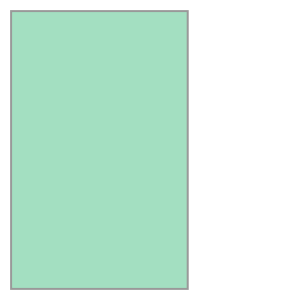

In [32]:
box(*lulc.rio.bounds())

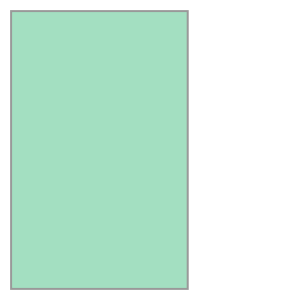

In [33]:
box(216580.0, 3540440.0, 783420.0, 4432060.0)

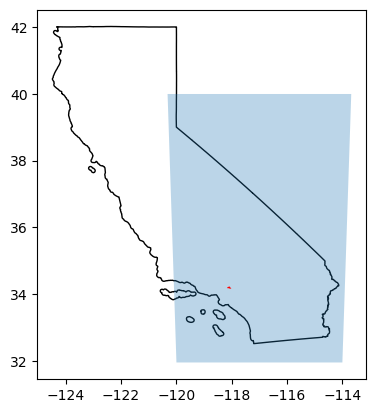

In [29]:

# Create GeoDataFrame from raster bounding box
lulc_bbox = gpd.GeoDataFrame(geometry = [box(*lulc.rio.bounds())],
                             crs = lulc.rio.crs)

# Plot raster boundary, fire perimeter, and CA boundary
fig, ax = plt.subplots()
ca.plot(ax=ax, color='white', edgecolor ='black')

# Reproject lulc_bbox and fire perimeter to match CA crs
lulc_bbox.to_crs(ca.crs).plot(ax=ax, alpha=0.3)
eaton.to_crs(ca.crs).plot(ax=ax, color='red')

plt.show()

## Clip raster to geometry
Check the no-data value: `rio.clip()` uses this value to fill pixels outside the perimeter

In [34]:
print('No-data value:', lulc.rio.nodata)

No-data value: 0


Clip in two steps:
1. `rio.clip.box()` to the perimeter's bounding box, then
2. `rio.clip()` to the perimeter itself

In [35]:
lulc.size

5054058808

In [37]:
# Match CRS and verify update
eaton_match = eaton.to_crs(lulc.rio.crs)
assert eaton_match.crs == lulc.rio.crs

In [38]:
# Clip raster to detailed geometry in two steps
lulc_step1 = lulc.rio.clip_box(*eaton_match.total_bounds)
lulc_step2 = lulc_step1.rio.clip(eaton_match.geometry)

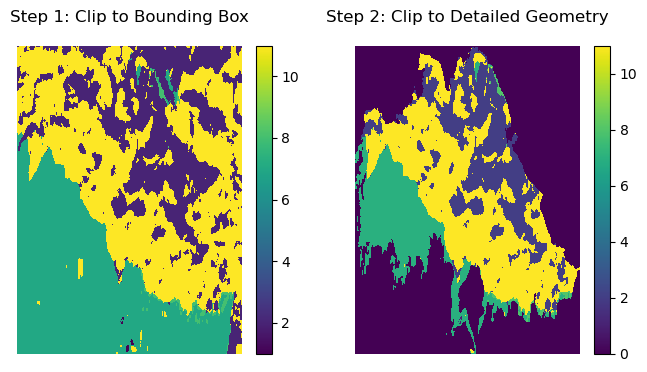

In [39]:
fig, ax = plt.subplots(1, 2, figsize=(8, 4))

lulc_step1.plot(ax=ax[0])
ax[0].set_title("Step 1: Clip to Bounding Box")
ax[0].axis("off")

lulc_step2.plot(ax=ax[1])
ax[1].set_title("Step 2: Clip to Detailed Geometry")
ax[1].axis("off")

plt.show()